In [ ]:
import sys
import json
from pathlib import Path
sys.path.append('../src/')
import numpy as np
import pandas as pd
from xpcs import th2q
import matplotlib.pyplot as plt

%matplotlib widget

In [ ]:
data = '/Users/your_username/Documents/Stycast/powderpattern_xy_collCode#9770.csv'
data1 = '/Users/your_username/data/XRD/Sulfides_XRD/Na3PS4_cubic.txt'
data2 = '/Users/your_username/data/XRD/Sulfides_XRD/Na3PS4_tet.txt'
data3 = '/Users/your_username/data/XRD/Sulfides_XRD/stycast_bulge_minus_glass.csv'

#data2 = '/Users/eriklamb/data/XRD/NBH/mo_JB_NBH_03_0001.txt'
### Output Directory ###
config_file = Path('../configs/config_NPS_2_data_090825.json')
with open(config_file, "r") as file:
    config = json.load(file)
figure_path = config_file.parent.parent / config.get("Figures")
figure_path.mkdir(parents=True, exist_ok=True)

Mo = 17.45

In [11]:
df = pd.read_csv(data, header=None, names=['x', 'y'])
df3 = pd.read_csv(data3,header=None,names=['a','b','c','d','e'])
df1 = np.loadtxt(data1)
df2 = np.loadtxt(data2)


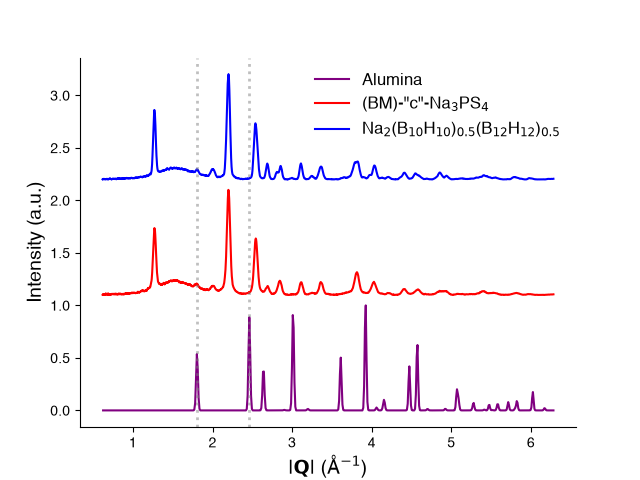

In [6]:
plt.rcParams['font.sans-serif'] = ['Helvetica']

q1 = np.array(df['x']) #Alumina
q2 = th2q(Mo,df1[:,0]) #Na3PS4
q3 = th2q(Mo,df2[:,0]) #Na2(B10H10)0.5(B12H12)0.5

I1 = np.array(df['y'])/np.max(df['y']) #Alumina
I2 = np.array(df1[:,1])/np.max(df1[:,1]) #Na3PS4
I3 = np.array(df2[:,1])/np.max(df2[:,1]) #Na2(B10H10)0.5(B12H12)0.5


mask1 = q1 > np.min(q3) 
mask2 = (q2 > np.min(q3)) & (q2 < np.max(q1))
mask3 = q3 < np.max(q1)


fig, ax = plt.subplots()
ax.plot(q1[mask1], I1[mask1],color='purple',label='Alumina')
ax.plot(q2[mask2], I2[mask2]/np.max(I2)+1.1,color='red',label=f'(BM)-"c"-Na$_3$PS$_4$')
ax.plot(q3[mask3], I3[mask3]/np.max(I3)+2.2,color='blue',label='Na$_2$(B$_{10}$H$_{10}$)$_{0.5}$(B$_{12}$H$_{12}$)$_{0.5}$')

ax.axvline(1.8, color="gray", ls=":",lw=2, alpha=0.5)
ax.axvline(2.46, color="gray", ls=":",lw=2, alpha=0.5)

ax.legend(fontsize=12,frameon=False)
ax.set_xlabel('|$\\bf{Q}$| (Å$^{-1}$)', fontsize=14)
ax.set_ylabel('Intensity (a.u.)', fontsize=14)
#ax.set_title('Alumina Powder Pattern', fontsize=16)

# Hide the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

fig.savefig(figure_path / f"alumina_powder_pattern.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})


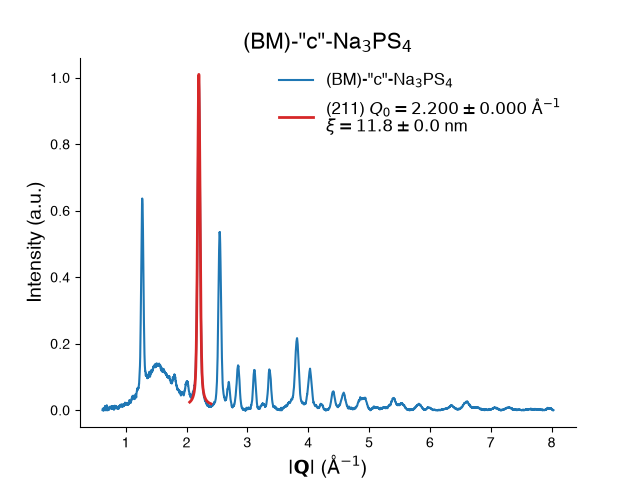

Q_peak = 2.2004 ± 0.0000 Å^-1
FWHM   = 0.0481 ± 0.0002 Å^-1
xi     = 11.76 ± 0.04 nm


In [7]:
from scipy.optimize import curve_fit
from xpcs import pseudo_voigt

# (221) peak of cubic Na3PS4
q_nps = th2q(Mo, df1[:, 0])
I_nps = df1[:, 1] / np.max(df1[:, 1])

q_lo, q_hi = 2.05, 2.40
pk = (q_nps > q_lo) & (q_nps < q_hi)
q_fit, y_fit = q_nps[pk], I_nps[pk]

i0 = int(np.argmax(y_fit))
fwhm0 = 0.02
p0 = [y_fit[i0] * fwhm0, q_fit[i0], fwhm0, 0.5, float(np.min(y_fit))]
bounds = (
    [0.0, q_lo, 1e-4, 0.0, -np.inf],
    [np.inf, q_hi, 0.2, 1.0, np.inf],
)
popt, pcov = curve_fit(pseudo_voigt, q_fit, y_fit, p0=p0, bounds=bounds, maxfev=20000)
perr = np.sqrt(np.diag(pcov))

Q_peak, Q_err = popt[1], perr[1]
fwhm, fwhm_err = popt[2], perr[2]
SCHERRER_K = 0.9
xi_A = 2.0 * np.pi * SCHERRER_K / fwhm
xi_err_A = abs(2.0 * np.pi * SCHERRER_K / fwhm**2 * fwhm_err)
xi_nm, xi_err_nm = xi_A * 0.1, xi_err_A * 0.1

q_line = np.linspace(q_lo, q_hi, 400)

fig, ax = plt.subplots()
ax.plot(q_nps, I_nps, color="C0", label='(BM)-"c"-Na$_3$PS$_4$')
ax.plot(
    q_line,
    pseudo_voigt(q_line, *popt),
    color="C3",
    lw=2,
    label=(
        rf"(211) $Q_0={Q_peak:.3f}\pm{Q_err:.3f}$ Å$^{{-1}}$"
        "\n"
        rf"$\xi={xi_nm:.1f}\pm{xi_err_nm:.1f}$ nm"
    ),
)
ax.set_xlabel('|$\\bf{Q}$| (Å$^{-1}$)', fontsize=14)
ax.set_ylabel('Intensity (a.u.)', fontsize=14)
ax.set_title('(BM)-"c"-Na$_3$PS$_4$', fontsize=16)
ax.legend(fontsize=12, frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

#fig.savefig(figure_path / "na3ps4_cubic.pdf", format="pdf", dpi=300, bbox_inches="tight", metadata={'Creator': ''})

print(f"Q_peak = {Q_peak:.4f} ± {Q_err:.4f} Å^-1")
print(f"FWHM   = {fwhm:.4f} ± {fwhm_err:.4f} Å^-1")
print(f"xi     = {xi_nm:.2f} ± {xi_err_nm:.2f} nm")


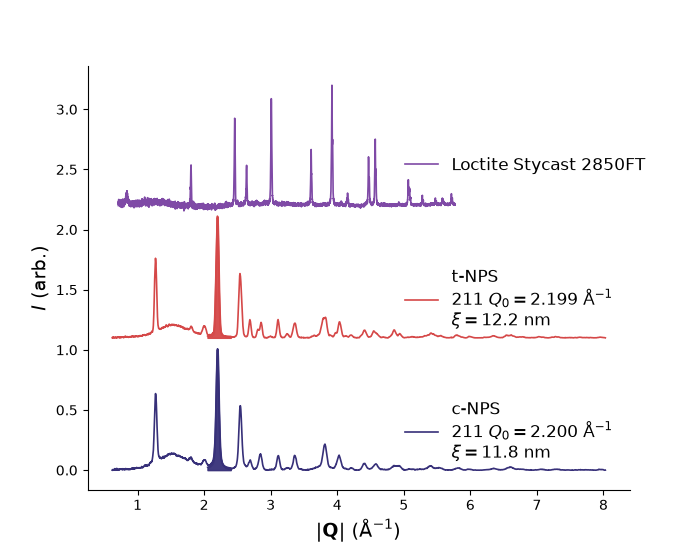

cubic  Q0=2.2004  FWHM=0.0481  xi=11.76 nm
tet    Q0=2.1988  FWHM=0.0465  xi=12.17 nm


In [13]:
from scipy.optimize import curve_fit
from xpcs import pseudo_voigt

SCHERRER_K = 0.9
q_lo, q_hi = 2.05, 2.40
offset = 1.1


def fit_peak(q, intensity):
    pk = (q > q_lo) & (q < q_hi)
    q_fit, y_fit = q[pk], intensity[pk]
    i0 = int(np.argmax(y_fit))
    fwhm0 = 0.02
    p0 = [y_fit[i0] * fwhm0, q_fit[i0], fwhm0, 0.5, float(np.min(y_fit))]
    bounds = (
        [0.0, q_lo, 1e-4, 0.0, -np.inf],
        [np.inf, q_hi, 0.2, 1.0, np.inf],
    )
    popt, pcov = curve_fit(pseudo_voigt, q_fit, y_fit, p0=p0, bounds=bounds, maxfev=20000)
    fwhm = popt[2]
    xi_nm = 2.0 * np.pi * SCHERRER_K / fwhm * 0.1
    return popt, xi_nm


q_c = th2q(Mo, df1[:, 0])
I_c = df1[:, 1] / np.max(df1[:, 1])
q_t = th2q(Mo, df2[:, 0])
I_t = df2[:, 1] / np.max(df2[:, 1])
# Convert the columns to float, then slice and normalize
I_s = (np.array(df3['e'])[1:]).astype(float)
I_s = I_s / np.max(I_s)
q_s = (np.array(df3['b'])[1:]).astype(float)

popt_c, xi_c = fit_peak(q_c, I_c)
popt_t, xi_t = fit_peak(q_t, I_t)
q_line = np.linspace(q_lo, q_hi, 400)

fig, ax = plt.subplots(figsize=(7, 5.5))

# bottom: BM cubic; top: HT tetragonal
fit_c = pseudo_voigt(q_line, *popt_c)
fit_t = pseudo_voigt(q_line, *popt_t)

(line_c,) = ax.plot(q_c, I_c, color="#373079", lw=1.2, zorder=3)
ax.fill_between(q_line, 0, fit_c, color="#373079", alpha=0.95, zorder=1)
ax.plot(q_line, fit_c, color="#373079", lw=1.0, zorder=2)

(line_t,) = ax.plot(q_t, I_t + offset, color="#d54848", lw=1.2, zorder=6)
ax.fill_between(q_line, offset, fit_t + offset, color="#d54848", alpha=0.95, zorder=4)
ax.plot(q_line, fit_t + offset, color="#d54848", lw=1.0, zorder=5)

(line_s,) = ax.plot(q_s, I_s + 2*offset, color="#7f4aa6", lw=1.2, zorder=6)

from matplotlib.transforms import blended_transform_factory

leg_transform = blended_transform_factory(ax.transAxes, ax.transData)
x_leg = 0.98


def legend_above(handle, label, y_above, x=None, loc="lower right"):
    return ax.legend(
        [handle],
        [label],
        loc=loc,
        bbox_to_anchor=(x_leg if x is None else x, y_above),
        bbox_transform=leg_transform,
        frameon=False,
        fontsize=12,
        borderaxespad=0.0,
    )


leg_c = legend_above(
    line_c,
    f'c-NPS\n211 $Q_0={popt_c[1]:.3f}$ Å$^{{-1}}$\n$\\xi={xi_c:.1f}$ nm',
    np.min(I_c),
)
ax.add_artist(leg_c)
leg_t = legend_above(
    line_t,
    f't-NPS\n211 $Q_0={popt_t[1]:.3f}$ Å$^{{-1}}$\n$\\xi={xi_t:.1f}$ nm',
    np.min(I_t + offset),
)
ax.add_artist(leg_t)
fig.canvas.draw()
_ax_box = ax.get_window_extent()
x_left = min(
    (leg.get_window_extent().x0 - _ax_box.x0) / _ax_box.width
    for leg in (leg_c, leg_t)
)
legend_above(
    line_s,
    "Loctite Stycast 2850FT",
    np.min(line_s.get_ydata())+0.25,
    x=x_left,
    loc="lower left",
)

ax.set_xlabel('|$\\bf{Q}$| (Å$^{-1}$)', fontsize=14)
ax.set_ylabel('$I$ (arb.)', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

fig.savefig(
    figure_path / "na3ps4_cubic_tet.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
    metadata={"Creator": ""},
)

print(f"cubic  Q0={popt_c[1]:.4f}  FWHM={popt_c[2]:.4f}  xi={xi_c:.2f} nm")
print(f"tet    Q0={popt_t[1]:.4f}  FWHM={popt_t[2]:.4f}  xi={xi_t:.2f} nm")
